In [1]:
import os, random
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.transforms import InterpolationMode
from sklearn.model_selection import train_test_split

def seed_everything(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [2]:
def find_file(name):
    for root, dirs, files in os.walk("/kaggle/input"):
        if name in files:
            return os.path.join(root, name)
    raise FileNotFoundError(name)

train_csv  = find_file("train.csv")
sample_csv = find_file("sample_submission.csv")
base_dir   = os.path.dirname(train_csv)
train_dir  = os.path.join(base_dir, "train_images")
test_dir   = os.path.join(base_dir, "test_images")

train_df = pd.read_csv(train_csv)
sub_df   = pd.read_csv(sample_csv)

classes = sorted(train_df["animal_class"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
idx_to_class = {i: c for c, i in class_to_idx.items()}
train_df["label"] = train_df["animal_class"].map(class_to_idx)

tr_df, val_df = train_test_split(
    train_df, test_size=0.15, stratify=train_df["label"], random_state=42
)
print(len(tr_df), len(val_df), len(classes))

2623 464 72


In [3]:
def color_key(arr):
    a = arr.astype(np.int32)
    return (a[..., 0] << 16) | (a[..., 1] << 8) | a[..., 2]

def permute_colors(arr, rng):
    """Give every distinct segment color a fresh random color."""
    key = color_key(arr).reshape(-1)
    uniq, inv = np.unique(key, return_inverse=True)
    palette = rng.integers(0, 256, size=(len(uniq), 3), dtype=np.uint8)
    return palette[inv.reshape(-1)].reshape(arr.shape)

def boundary_map(arr):
    """White outlines where neighbouring segments differ, black elsewhere."""
    key = color_key(arr)
    edge = np.zeros(key.shape, dtype=bool)
    edge[:, :-1] |= key[:, :-1] != key[:, 1:]
    edge[:-1, :] |= key[:-1, :] != key[1:, :]
    out = (edge * 255).astype(np.uint8)
    return np.stack([out] * 3, axis=-1)

In [4]:
IMG_SIZE = 224
MODE = "permute"   # "permute" or "boundary"

class SegMapDataset(Dataset):
    def __init__(self, df, image_dir, train=True, mode="permute", img_size=224, has_label=True):
        self.df = df.reset_index(drop=True)
        self.image_dir, self.train, self.mode, self.has_label = image_dir, train, mode, has_label

        # NEAREST everywhere so no blended colors are created at segment edges
        self.resize = transforms.Resize((img_size, img_size), interpolation=InterpolationMode.NEAREST)
        self.aug = transforms.Compose([
            transforms.RandomHorizontalFlip(),
            transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.9, 1.1),
                                    interpolation=InterpolationMode.NEAREST),
        ])
        self.finish = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
        ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(os.path.join(self.image_dir, row["image_id"])).convert("RGB")
        img = self.resize(img)
        if self.train:
            img = self.aug(img)
        arr = np.array(img)

        if self.mode == "permute":
            # random colors in training, fixed deterministic colors at eval time
            rng = np.random.default_rng() if self.train else np.random.default_rng(0)
            arr = permute_colors(arr, rng)
        elif self.mode == "boundary":
            arr = boundary_map(arr)

        x = self.finish(Image.fromarray(arr))
        if self.has_label:
            return x, torch.tensor(row["label"], dtype=torch.long)
        return x, row["image_id"]

train_ds = SegMapDataset(tr_df,  train_dir, train=True,  mode=MODE, img_size=IMG_SIZE)
val_ds   = SegMapDataset(val_df, train_dir, train=False, mode=MODE, img_size=IMG_SIZE)
test_ds  = SegMapDataset(sub_df, test_dir,  train=False, mode=MODE, img_size=IMG_SIZE, has_label=False)

BS = 32
train_loader = DataLoader(train_ds, batch_size=BS, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BS, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BS, shuffle=False, num_workers=2, pin_memory=True)

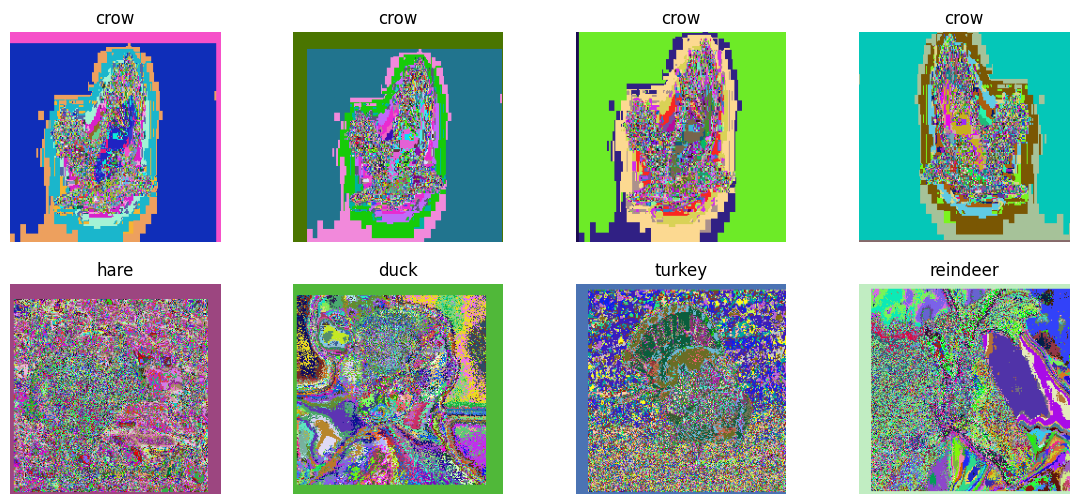

In [5]:
inv_mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
inv_std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axs = plt.subplots(2, 4, figsize=(14, 6))
for k in range(4):
    x, y = train_ds[0]                      # same image, re-augmented each call
    axs[0, k].imshow((x * inv_std + inv_mean).clamp(0, 1).permute(1, 2, 0))
    axs[0, k].set_title(idx_to_class[y.item()]); axs[0, k].axis("off")
for k in range(4):
    x, y = train_ds[k + 1]
    axs[1, k].imshow((x * inv_std + inv_mean).clamp(0, 1).permute(1, 2, 0))
    axs[1, k].set_title(idx_to_class[y.item()]); axs[1, k].axis("off")
plt.show()

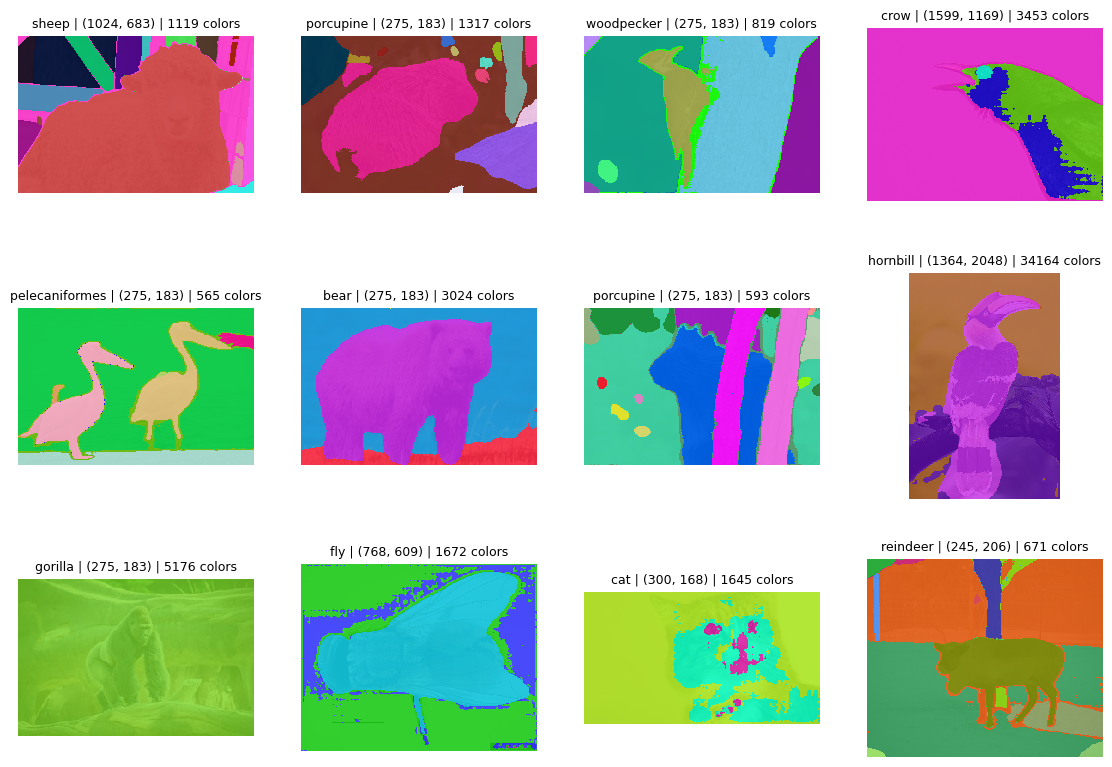

unique colors  min/median/max: 122 1625.5 46020


In [6]:
import glob
sample = tr_df.sample(12, random_state=0)
fig, axs = plt.subplots(3, 4, figsize=(14, 10))
for ax, (_, r) in zip(axs.ravel(), sample.iterrows()):
    im = Image.open(os.path.join(train_dir, r["image_id"])).convert("RGB")
    arr = np.array(im)
    n_unique = len(np.unique(color_key(arr)))
    ax.imshow(arr, interpolation="nearest")
    ax.set_title(f'{r["animal_class"]} | {im.size} | {n_unique} colors', fontsize=9)
    ax.axis("off")
plt.show()

# distribution over 300 images
counts = [len(np.unique(color_key(np.array(Image.open(os.path.join(train_dir, f)).convert("RGB")))))
          for f in tr_df["image_id"].sample(300, random_state=1)]
print("unique colors  min/median/max:", np.min(counts), np.median(counts), np.max(counts))

In [7]:
IMG_SIZE = 256   # try 288 or 320 later

def random_channel_shuffle(x):          # x: tensor 3xHxW, tint hue means nothing
    return x[torch.randperm(3)]

class SegMapDataset(Dataset):
    def __init__(self, df, image_dir, train=True, img_size=256, has_label=True):
        self.df = df.reset_index(drop=True)
        self.image_dir, self.has_label = image_dir, has_label
        norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        bicubic = InterpolationMode.BICUBIC
        if train:
            self.tf = transforms.Compose([
                transforms.RandomResizedCrop(img_size, scale=(0.5, 1.0),
                                             ratio=(0.75, 1.5), interpolation=bicubic),
                transforms.RandomHorizontalFlip(),
                transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.3, hue=0.5),
                transforms.RandomGrayscale(p=0.2),
                transforms.ToTensor(),
                transforms.Lambda(random_channel_shuffle),
                norm,
            ])
        else:
            self.tf = transforms.Compose([
                transforms.Resize((img_size, img_size), interpolation=bicubic),
                transforms.ToTensor(),
                norm,
            ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(os.path.join(self.image_dir, row["image_id"])).convert("RGB")
        x = self.tf(img)
        if self.has_label:
            return x, torch.tensor(row["label"], dtype=torch.long)
        return x, row["image_id"]

train_ds = SegMapDataset(tr_df,  train_dir, train=True,  img_size=IMG_SIZE)
val_ds   = SegMapDataset(val_df, train_dir, train=False, img_size=IMG_SIZE)
test_ds  = SegMapDataset(sub_df, test_dir,  train=False, img_size=IMG_SIZE, has_label=False)

BS = 32
train_loader = DataLoader(train_ds, batch_size=BS, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BS, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BS, shuffle=False, num_workers=2, pin_memory=True)

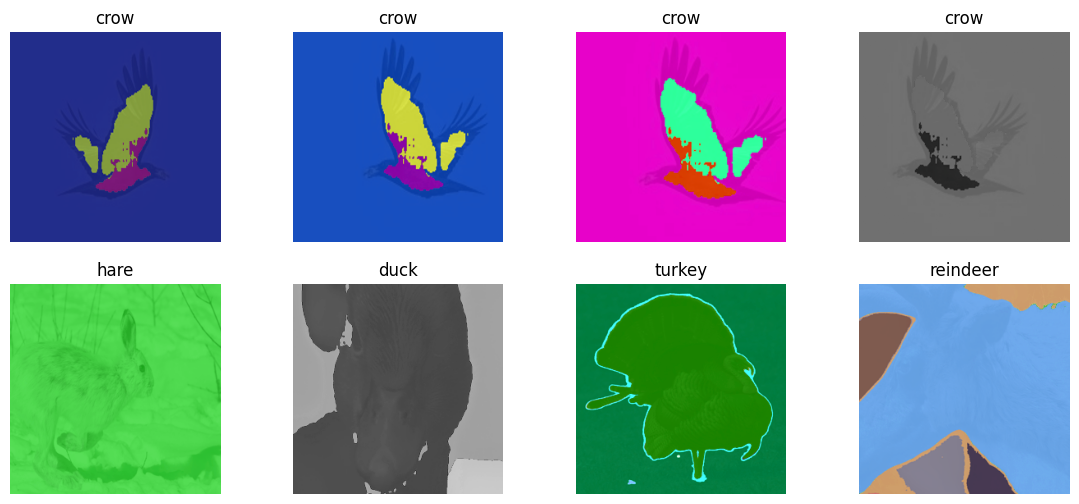

In [8]:
inv_mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
inv_std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axs = plt.subplots(2, 4, figsize=(14, 6))
for k in range(4):
    x, y = train_ds[0]                      # same image, re-augmented each call
    axs[0, k].imshow((x * inv_std + inv_mean).clamp(0, 1).permute(1, 2, 0))
    axs[0, k].set_title(idx_to_class[y.item()]); axs[0, k].axis("off")
for k in range(4):
    x, y = train_ds[k + 1]
    axs[1, k].imshow((x * inv_std + inv_mean).clamp(0, 1).permute(1, 2, 0))
    axs[1, k].set_title(idx_to_class[y.item()]); axs[1, k].axis("off")
plt.show()

In [9]:
model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.DEFAULT)
model.classifier[2] = nn.Linear(model.classifier[2].in_features, len(classes))
model = model.to(device)

EPOCHS = 15
loss_fn   = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=0.05)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler    = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 212MB/s] 
/tmp/ipykernel_46/3130054374.py:9: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler    = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


Epoch 1/15 [train]:   0%|          | 0/82 [00:00<?, ?it/s]

Epoch 1/15 [val]  :   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 01/15 | train loss 3.929 acc 0.120 | val loss 3.967 acc 0.114 | lr 9.57e-05 | 72s  <- saved best


Epoch 2/15 [train]:   0%|          | 0/82 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ab3f9d9ae80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ab3f9d9ae80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

...

Epoch 15/15 [train]:   0%|          | 0/82 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ab3f9d9ae80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ab3f9d9ae80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 15/15 [val]  :   0%|          | 0/15 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ab3f9d9ae80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ab3f9d9ae80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 15/15 | train loss 2.117 acc 0.684 | val loss 2.024 acc 0.681 | lr 1.09e-06 | 69s

Best val acc: 0.6810


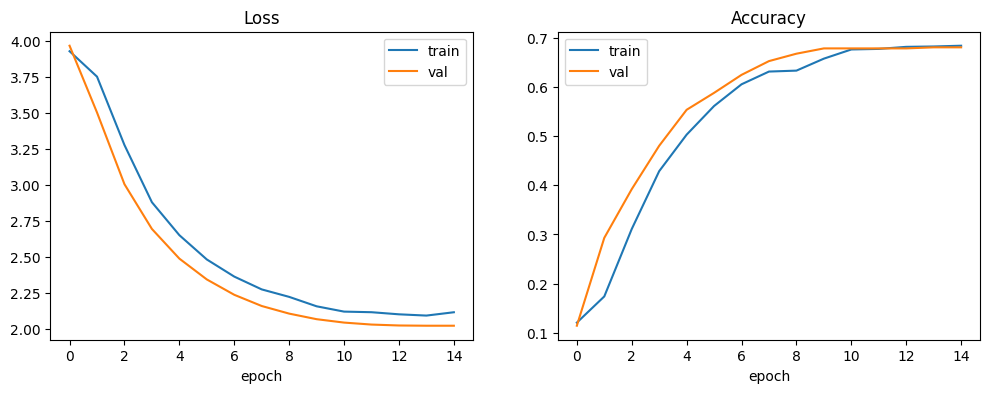

In [11]:
import time
from tqdm.auto import tqdm

def run_epoch(loader, train, desc):
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    bar = tqdm(loader, desc=desc, leave=False)
    with torch.set_grad_enabled(train):
        for x, y in bar:
            x, y = x.to(device), y.to(device)
            with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):
                out = model(x)
                loss = loss_fn(out, y)
            if train:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)
            bar.set_postfix(loss=f"{total_loss/n:.3f}", acc=f"{correct/n:.3f}")
    return total_loss / n, correct / n

history = {"tl": [], "ta": [], "vl": [], "va": []}
best_acc = 0

for ep in range(EPOCHS):
    t0 = time.time()
    tl, ta = run_epoch(train_loader, True,  f"Epoch {ep+1}/{EPOCHS} [train]")
    vl, va = run_epoch(val_loader,   False, f"Epoch {ep+1}/{EPOCHS} [val]  ")
    scheduler.step()

    history["tl"].append(tl); history["ta"].append(ta)
    history["vl"].append(vl); history["va"].append(va)

    saved = ""
    if va > best_acc:
        best_acc = va
        torch.save(model.state_dict(), "best.pt")
        saved = "  <- saved best"

    print(f"Epoch {ep+1:02d}/{EPOCHS} | "
          f"train loss {tl:.3f} acc {ta:.3f} | "
          f"val loss {vl:.3f} acc {va:.3f} | "
          f"lr {optimizer.param_groups[0]['lr']:.2e} | "
          f"{time.time()-t0:.0f}s{saved}")

print(f"\nBest val acc: {best_acc:.4f}")

# Curves
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(history["tl"], label="train"); axs[0].plot(history["vl"], label="val")
axs[0].set_title("Loss"); axs[0].set_xlabel("epoch"); axs[0].legend()
axs[1].plot(history["ta"], label="train"); axs[1].plot(history["va"], label="val")
axs[1].set_title("Accuracy"); axs[1].set_xlabel("epoch"); axs[1].legend()
plt.show()

Epoch 16/30 [train]:   0%|          | 0/82 [00:00<?, ?it/s]

Epoch 16/30 [val]  :   0%|          | 0/15 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ab3f9d9ae80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ab3f9d9ae80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 16/30 | train loss 1.721 acc 0.782 | val loss 1.290 acc 0.875 | lr 9.89e-05 | 69s  <- saved best


Epoch 17/30 [train]:   0%|          | 0/82 [00:00<?, ?it/s]

...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ab3f9d9ae80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ab3f9d9ae80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 30/30 [train]:   0%|          | 0/82 [00:01<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ab3f9d9ae80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ab3f9d9ae80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 30/30 [val]  :   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 30/30 | train loss 0.805 acc 0.995 | val loss 0.904 acc 0.955 | lr 0.00e+00 | 68s  <- saved best

Best val acc: 0.9547


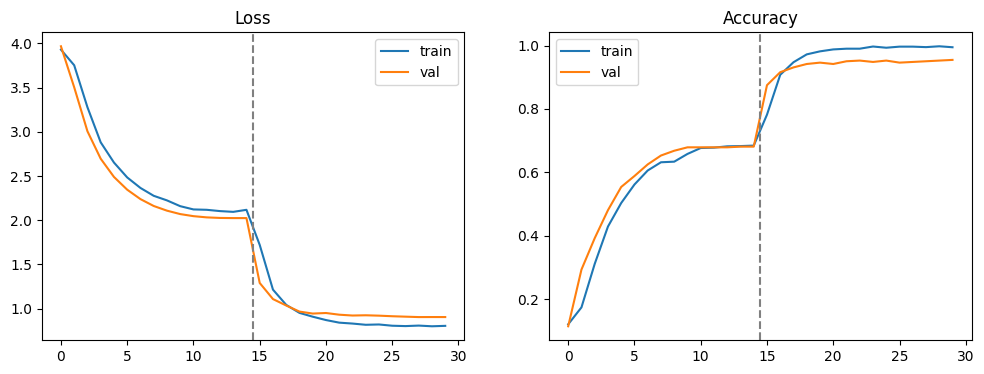

In [12]:
# Continue from the current weights with a fresh cosine cycle (warm restart)
EPOCHS2 = 15
model.load_state_dict(torch.load("best.pt", map_location=device))   # start from the best checkpoint

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=0.05)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS2)
scaler    = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

try:
    best_acc
except NameError:
    best_acc = 0.681        # in case the kernel was restarted

start = len(history["tl"]) if "history" in globals() else 0
if "history" not in globals():
    history = {"tl": [], "ta": [], "vl": [], "va": []}

for ep in range(EPOCHS2):
    t0 = time.time()
    tl, ta = run_epoch(train_loader, True,  f"Epoch {start+ep+1}/{start+EPOCHS2} [train]")
    vl, va = run_epoch(val_loader,   False, f"Epoch {start+ep+1}/{start+EPOCHS2} [val]  ")
    scheduler.step()

    history["tl"].append(tl); history["ta"].append(ta)
    history["vl"].append(vl); history["va"].append(va)

    saved = ""
    if va > best_acc:
        best_acc = va
        torch.save(model.state_dict(), "best.pt")
        saved = "  <- saved best"

    print(f"Epoch {start+ep+1:02d}/{start+EPOCHS2} | "
          f"train loss {tl:.3f} acc {ta:.3f} | "
          f"val loss {vl:.3f} acc {va:.3f} | "
          f"lr {optimizer.param_groups[0]['lr']:.2e} | "
          f"{time.time()-t0:.0f}s{saved}")

print(f"\nBest val acc: {best_acc:.4f}")

# Curves across all epochs so far
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(history["tl"], label="train"); axs[0].plot(history["vl"], label="val")
axs[0].axvline(start - 0.5, color="gray", ls="--"); axs[0].set_title("Loss"); axs[0].legend()
axs[1].plot(history["ta"], label="train"); axs[1].plot(history["va"], label="val")
axs[1].axvline(start - 0.5, color="gray", ls="--"); axs[1].set_title("Accuracy"); axs[1].legend()
plt.show()

In [13]:
model.load_state_dict(torch.load("best.pt", map_location=device))
model.eval()

ids, preds = [], []
with torch.no_grad():
    for x, image_ids in test_loader:
        out = model(x.to(device))
        preds += [idx_to_class[p.item()] for p in out.argmax(1)]
        ids += list(image_ids)

submission = pd.DataFrame({"image_id": ids, "animal_class": preds})
submission.to_csv("submission.csv", index=False)
print(submission.head(), len(submission))

                               image_id animal_class
0          6eab26f8b156fda90e1bc819.png   woodpecker
1  483f71af1c174ab2a0c31a836267227d.png     antelope
2  563878772a3f47ce98cf9c10039a0219.png   chimpanzee
3  9aa782974228482390c1a237408a967a.png      hamster
4  3ed553219cf049b8bd9a65c300b02fb0.png          cat 1179


In [16]:
import torch.nn.functional as F

In [17]:
import torch.nn.functional as F

def probs_of(loader):
    model.eval(); P = []
    with torch.no_grad():
        for x, _ in loader:
            P.append(F.softmax(model(x.to(device)), 1).cpu())
    return torch.cat(P)

def feats_of(loader):
    model.eval(); out = []
    with torch.no_grad():
        for x, _ in loader:
            x = model.avgpool(model.features(x.to(device)))
            f = model.classifier[:2](x)                     # pooled embedding
            out.append(F.normalize(f, dim=1).cpu())
    return torch.cat(out)

tr_eval = DataLoader(SegMapDataset(tr_df, train_dir, train=False, img_size=IMG_SIZE),
                     batch_size=64, shuffle=False, num_workers=2)
ftr, fva, fte = feats_of(tr_eval), feats_of(val_loader), feats_of(test_loader)

sim_val  = (fva @ ftr.T).max(1)[0]
sim_test = (fte @ ftr.T).max(1)[0]
print("nearest-train similarity  val: median %.3f, >0.95: %.1f%%" % (sim_val.median(), 100*(sim_val>0.95).float().mean()))
print("nearest-train similarity test: median %.3f, >0.95: %.1f%%" % (sim_test.median(), 100*(sim_test>0.95).float().mean()))

pv, pt = probs_of(val_loader), probs_of(test_loader)
print("mean max-confidence  val: %.3f | test: %.3f" % (pv.max(1)[0].mean(), pt.max(1)[0].mean()))

nearest-train similarity  val: median 0.892, >0.95: 21.8%
nearest-train similarity test: median 0.869, >0.95: 15.9%
mean max-confidence  val: 0.825 | test: 0.805


In [18]:
# 1) End-to-end check: push val images through the *submission* path
chk_ds = SegMapDataset(val_df, train_dir, train=False, img_size=IMG_SIZE, has_label=False)
chk_ld = DataLoader(chk_ds, batch_size=32, shuffle=False, num_workers=2)

model.load_state_dict(torch.load("best.pt", map_location=device)); model.eval()
ids, preds = [], []
with torch.no_grad():
    for x, image_ids in chk_ld:
        preds += [idx_to_class[p.item()] for p in model(x.to(device)).argmax(1)]
        ids += list(image_ids)

chk = val_df[["image_id", "animal_class"]].merge(
    pd.DataFrame({"image_id": ids, "pred": preds}), on="image_id")
print("val accuracy via submission path:", (chk["animal_class"] == chk["pred"]).mean())

# 2) Inspect the file you will actually upload
sub = pd.read_csv("submission.csv")
print(sub.shape, list(sub.columns))
print("sample file classes:", pd.read_csv(sample_csv)["animal_class"].nunique(), "unique values")
print("submission classes :", sub["animal_class"].nunique(), "unique values")
print(sub["animal_class"].value_counts().head(8))
print("file modified:", time.ctime(os.path.getmtime("submission.csv")))

val accuracy via submission path: 0.9547413793103449
(1179, 2) ['image_id', 'animal_class']
sample file classes: 1 unique values
submission classes : 72 unique values
animal_class
cockroach     22
wolf          21
rat           21
rhinoceros    21
pigeon        21
woodpecker    20
bee           20
dolphin       20
Name: count, dtype: int64
file modified: Fri Oct  9 10:26:46 2026


In [19]:
model.load_state_dict(torch.load("best.pt", map_location=device)); model.eval()
ids, preds = [], []
with torch.no_grad():
    for x, image_ids in test_loader:
        preds += [idx_to_class[p.item()] for p in model(x.to(device)).argmax(1)]
        ids += list(image_ids)

sample = pd.read_csv(sample_csv)
submission = sample[["image_id"]].merge(pd.DataFrame({"image_id": ids, "animal_class": preds}), on="image_id", how="left")
assert submission["animal_class"].notna().all() and len(submission) == 1179
submission.to_csv("submission_v2.csv", index=False)
print(submission["animal_class"].value_counts().head(), time.ctime())

animal_class
cockroach     22
wolf          21
rat           21
rhinoceros    21
pigeon        21
Name: count, dtype: int64 Fri Oct  9 10:40:33 2026


In [20]:
import numpy as np, torch, torch.nn.functional as F
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold

# Fresh ImageNet-pretrained backbone (NOT your fine-tuned model)
fe = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.DEFAULT).to(device).eval()
fe.classifier[2] = nn.Identity()          # output = pooled 768-d embedding

def embed(df, d):
    ds = SegMapDataset(df, d, train=False, img_size=IMG_SIZE, has_label=False)
    ld = DataLoader(ds, batch_size=64, shuffle=False, num_workers=2)
    out = []
    with torch.no_grad():
        for x, _ in ld:
            out.append(F.normalize(fe(x.to(device)), dim=1).cpu())
    return torch.cat(out)

E = embed(train_df, train_dir)                     # all 3087 train images
S = E @ E.T
S.fill_diagonal_(0)

# 1) how many train images have a near-twin, and do twins share a label?
nn_sim, nn_idx = S.max(1)
lab = torch.tensor(train_df["label"].values)
for t in (0.90, 0.95, 0.98):
    m = nn_sim > t
    print(f"sim>{t}: {m.float().mean()*100:.1f}% of train images have a twin; "
          f"same label: {(lab[m] == lab[nn_idx[m]]).float().mean()*100:.1f}%")

# 2) how leaky was your old val split?
val_pos = train_df.index.get_indexer(val_df.index)
tr_pos  = train_df.index.get_indexer(tr_df.index)
leak = (S[val_pos][:, tr_pos].max(1)[0] > 0.95).float().mean()
print(f"old val images with a >0.95 twin in old train: {leak*100:.1f}%")

# 3) group near-duplicates and make an honest grouped split
THR = 0.95
_, group = connected_components(csr_matrix((S > THR).numpy()), directed=False)
print("groups:", group.max() + 1, "for", len(train_df), "images")

sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_i, va_i = next(sgkf.split(train_df, train_df["label"], groups=group))
tr_df2, val_df2 = train_df.iloc[tr_i], train_df.iloc[va_i]
print(len(tr_df2), len(val_df2), "| classes in val:", val_df2["label"].nunique())

sim>0.9: 1.4% of train images have a twin; same label: 95.2%
sim>0.95: 0.1% of train images have a twin; same label: 100.0%
sim>0.98: 0.0% of train images have a twin; same label: nan%
old val images with a >0.95 twin in old train: 0.2%
groups: 3085 for 3087 images
2574 513 | classes in val: 72


In [21]:
from transformers import AutoModel
from sklearn.linear_model import LogisticRegression

bb = AutoModel.from_pretrained("facebook/dinov2-base").to(device).eval()
if device.type == "cuda":
    bb = bb.half()

tf = transforms.Compose([
    transforms.Resize((224, 224), interpolation=InterpolationMode.BICUBIC),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

class Raw(Dataset):
    def __init__(self, ids, d): self.ids, self.d = list(ids), d
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        im = Image.open(os.path.join(self.d, self.ids[i])).convert("RGB")
        return tf(im), tf(im.convert("L").convert("RGB"))

@torch.no_grad()
def extract(ids, d):
    ld = DataLoader(Raw(ids, d), batch_size=64, shuffle=False, num_workers=2)
    feats = []
    for a, g in ld:
        views = [a, a.flip(-1), g, g.flip(-1)]
        acc = 0
        for v in views:
            v = v.to(device)
            if device.type == "cuda": v = v.half()
            h = bb(pixel_values=v).last_hidden_state
            e = torch.cat([h[:, 0], h[:, 1:].mean(1)], dim=1).float()
            acc = acc + F.normalize(e, dim=1)
        feats.append(F.normalize(acc, dim=1).cpu())
    return torch.cat(feats).numpy()

Xtr  = extract(train_df["image_id"], train_dir)
Xte  = extract(sub_df["image_id"],  test_dir)
ytr  = train_df["label"].values
print(Xtr.shape, Xte.shape)

# Quick check on a held-out split (the grouped split from before)
for C in (1, 10, 50):
    clf = LogisticRegression(C=C, max_iter=3000)
    clf.fit(Xtr[tr_i], ytr[tr_i])
    print(f"C={C}: val acc {clf.score(Xtr[va_i], ytr[va_i]):.4f}")

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

(3087, 1536) (1179, 1536)
C=1: val acc 0.9220
C=10: val acc 0.9493
C=50: val acc 0.9493


In [22]:
BEST_C = 10   # set to the best value from the loop above

clf = LogisticRegression(C=BEST_C, max_iter=3000)
clf.fit(Xtr, ytr)                                   # all 3087 images
pred = clf.predict(Xte)

submission = pd.DataFrame({"image_id": sub_df["image_id"],
                           "animal_class": [idx_to_class[p] for p in pred]})
assert len(submission) == 1179 and submission["animal_class"].notna().all()
submission.to_csv("submission_dino.csv", index=False)
print(submission["animal_class"].nunique(), "classes predicted")

72 classes predicted


In [23]:
# --- keep the base features, then extract DINOv2-large features ---
Xtr_b, Xte_b = Xtr, Xte
del bb
if device.type == "cuda": torch.cuda.empty_cache()

bb = AutoModel.from_pretrained("facebook/dinov2-large").to(device).eval()
if device.type == "cuda": bb = bb.half()

Xtr_l = extract(train_df["image_id"], train_dir)
Xte_l = extract(sub_df["image_id"],  test_dir)
print(Xtr_b.shape, Xtr_l.shape)

# --- held-out check on the grouped split: base vs large vs average ---
def probs(Xa, ya, Xb, C=10):
    clf = LogisticRegression(C=C, max_iter=3000).fit(Xa, ya)
    return clf.predict_proba(Xb)

Pb = probs(Xtr_b[tr_i], ytr[tr_i], Xtr_b[va_i])
Pl = probs(Xtr_l[tr_i], ytr[tr_i], Xtr_l[va_i])
for name, P in [("base", Pb), ("large", Pl), ("avg", (Pb + Pl) / 2)]:
    print(f"{name:5s} val acc: {(P.argmax(1) == ytr[va_i]).mean():.4f}")

config.json:   0%|          | 0.00/549 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.22GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/439 [00:00<?, ?it/s]

(3087, 1536) (3087, 2048)
base  val acc: 0.9493
large val acc: 0.9805
avg   val acc: 0.9786


In [24]:
from scipy.optimize import linear_sum_assignment

Pt = (probs(Xtr_b, ytr, Xte_b) + probs(Xtr_l, ytr, Xte_l)) / 2   # test probabilities

# File 1: plain argmax of the averaged probabilities
pred = Pt.argmax(1)
sub1 = pd.DataFrame({"image_id": sub_df["image_id"],
                     "animal_class": [idx_to_class[p] for p in pred]})
sub1.to_csv("submission_ens.csv", index=False)

# File 2: same, but no class may be predicted more than CAP times
CAP = 19                                   # test looks like ~16 per class; 19 only blocks extremes
cost = -np.log(np.repeat(Pt + 1e-9, CAP, axis=1))   # each class gets CAP "slots"
r, c = linear_sum_assignment(cost)
pred_bal = np.empty(len(Pt), dtype=int)
pred_bal[r] = c // CAP
sub2 = pd.DataFrame({"image_id": sub_df["image_id"],
                     "animal_class": [idx_to_class[p] for p in pred_bal]})
sub2.to_csv("submission_ens_capped.csv", index=False)

print("changed by capping:", (pred != pred_bal).sum(), "images")
print("max predicted count  plain:", np.bincount(pred, minlength=72).max(),
      "| capped:", np.bincount(pred_bal, minlength=72).max())

changed by capping: 9 images
max predicted count  plain: 22 | capped: 19


In [25]:
del bb
if device.type == "cuda": torch.cuda.empty_cache()

bb = AutoModel.from_pretrained("facebook/dinov2-giant").to(device).eval()
if device.type == "cuda": bb = bb.half()

Xtr_g = extract(train_df["image_id"], train_dir)
Xte_g = extract(sub_df["image_id"],  test_dir)
print(Xtr_g.shape)

Pb = probs(Xtr_b[tr_i], ytr[tr_i], Xtr_b[va_i])
Pl = probs(Xtr_l[tr_i], ytr[tr_i], Xtr_l[va_i])
Pg = probs(Xtr_g[tr_i], ytr[tr_i], Xtr_g[va_i])
for name, P in [("giant", Pg), ("large", Pl), ("large+giant", (Pl + Pg) / 2),
                ("base+large+giant", (Pb + Pl + Pg) / 3)]:
    print(f"{name:18s} val acc: {(P.argmax(1) == ytr[va_i]).mean():.4f}")

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 4.55GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/727 [00:00<?, ?it/s]

(3087, 3072)
giant              val acc: 0.9903
large              val acc: 0.9805
large+giant        val acc: 0.9844
base+large+giant   val acc: 0.9844


In [26]:
from scipy.optimize import linear_sum_assignment

FEATS = [(Xtr_l, Xte_l), (Xtr_g, Xte_g)]     # e.g. large + giant; change after seeing val

def ens_probs(feats, y, extra_idx=None, y_extra=None):
    out = 0
    for Xt, Xe in feats:
        if extra_idx is None:
            Xa, ya = Xt, y
        else:
            Xa, ya = np.vstack([Xt, Xe[extra_idx]]), np.concatenate([y, y_extra])
        out = out + probs(Xa, ya, Xe)
    return out / len(feats)

def cap_assign(P, CAP=19):
    cost = -np.log(np.repeat(P + 1e-9, CAP, axis=1))
    r, c = linear_sum_assignment(cost)
    pred = np.empty(len(P), dtype=int); pred[r] = c // CAP
    return pred

def save(pred, name):
    pd.DataFrame({"image_id": sub_df["image_id"],
                  "animal_class": [idx_to_class[p] for p in pred]}).to_csv(name, index=False)

# A) no pseudo-labels
Pt  = ens_probs(FEATS, ytr)
save(cap_assign(Pt), "sub_A_capped.csv")

# B) pseudo-labels from confident test predictions, then refit
keep = Pt.max(1) > 0.80
print("pseudo-labelled:", keep.sum(), "of", len(Pt))
Pt2 = ens_probs(FEATS, ytr, np.where(keep)[0], Pt.argmax(1)[keep])
save(cap_assign(Pt2), "sub_B_pl_capped.csv")

print("B vs A changed:", (cap_assign(Pt2) != cap_assign(Pt)).sum(), "images")

pseudo-labelled: 995 of 1179
B vs A changed: 1 images


In [28]:
@torch.no_grad()
def clip_embed(v):
    h = clip.vision_model(pixel_values=v).pooler_output     # pooled vision features
    return clip.visual_projection(h)                        # same as get_image_features

@torch.no_grad()
def extract_clip(ids, d):
    feats = []
    for a, g in DataLoader(RawC(ids, d), batch_size=64, shuffle=False, num_workers=2):
        acc = 0
        for v in [a, a.flip(-1), g, g.flip(-1)]:
            v = v.to(device)
            if device.type == "cuda": v = v.half()
            acc = acc + F.normalize(clip_embed(v).float(), dim=1)
        feats.append(F.normalize(acc, dim=1).cpu())
    return torch.cat(feats).numpy()

Xtr_c = extract_clip(train_df["image_id"], train_dir)
Xte_c = extract_clip(sub_df["image_id"],  test_dir)
print(Xtr_c.shape, Xte_c.shape)

# every backbone extracted so far
cands = {}
for name, (a, b) in {"base": ("Xtr_b", "Xte_b"), "large": ("Xtr_l", "Xte_l"),
                     "giant": ("Xtr_g", "Xte_g"), "clip": ("Xtr_c", "Xte_c")}.items():
    if a in globals() and b in globals():
        cands[name] = (globals()[a], globals()[b])

vp = {k: probs(Xt[tr_i], ytr[tr_i], Xt[va_i]) for k, (Xt, _) in cands.items()}
accs = {k: (P.argmax(1) == ytr[va_i]).mean() for k, P in vp.items()}
for k, a in accs.items(): print(f"{k:6s} val acc {a:.4f}")

chosen = [k for k, a in accs.items() if a >= max(accs.values()) - 0.01]
Pv = sum(vp[k] for k in chosen) / len(chosen)
print("chosen:", chosen, "| ensemble val acc:", round((Pv.argmax(1) == ytr[va_i]).mean(), 4))

(3087, 768) (1179, 768)
base   val acc 0.9493
large  val acc 0.9805
giant  val acc 0.9903
clip   val acc 0.8674
chosen: ['large', 'giant'] | ensemble val acc: 0.9844


In [29]:
FEATS = [cands[k] for k in chosen]
Pt = ens_probs(FEATS, ytr)                      # fits on all 3087 train images

def cap_min_assign(P, CAP=19, MIN=None, BONUS=3.0):
    cost = -np.log(np.repeat(P + 1e-9, CAP, axis=1))
    for cls, mn in (MIN or {}).items():
        cost[:, cls*CAP : cls*CAP + mn] -= BONUS
    r, c = linear_sum_assignment(cost)
    pred = np.empty(len(P), dtype=int); pred[r] = c // CAP
    return pred

pred_cap = cap_min_assign(Pt)
save(pred_cap, "sub_D_cap.csv")

counts = np.bincount(pred_cap, minlength=72)
low = {c: 10 for c in np.where(counts < 10)[0]}
print("classes predicted <10 times:", {idx_to_class[c]: int(counts[c]) for c in low})
pred_min = cap_min_assign(Pt, MIN=low)
save(pred_min, "sub_D_cap_min.csv")
print("min-count changed", (pred_min != pred_cap).sum(), "images")

classes predicted <10 times: {'goose': 9, 'gorilla': 9, 'grasshopper': 9, 'hamster': 9, 'hedgehog': 9, 'hippopotamus': 9, 'hornbill': 9, 'horse': 9, 'hummingbird': 9, 'hyena': 9, 'jellyfish': 4}
min-count changed 11 images


In [30]:
globals().pop("clip", None); globals().pop("bb", None)
if device.type == "cuda": torch.cuda.empty_cache()

bb = AutoModel.from_pretrained("facebook/dinov2-large").to(device).eval()
if device.type == "cuda": bb = bb.half()

def extract_size(ids, d, size):
    tfm = transforms.Compose([
        transforms.Resize((size, size), interpolation=InterpolationMode.BICUBIC),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ])
    class R(Dataset):
        def __len__(s): return len(ids)
        def __getitem__(s, i):
            im = Image.open(os.path.join(d, list(ids)[i])).convert("RGB")
            return tfm(im), tfm(im.convert("L").convert("RGB"))
    feats = []
    with torch.no_grad():
        for a, g in DataLoader(R(), batch_size=32, shuffle=False, num_workers=2):
            acc = 0
            for v in [a, a.flip(-1), g, g.flip(-1)]:
                v = v.to(device)
                if device.type == "cuda": v = v.half()
                h = bb(pixel_values=v).last_hidden_state
                e = torch.cat([h[:, 0], h[:, 1:].mean(1)], dim=1).float()
                acc = acc + F.normalize(e, dim=1)
            feats.append(F.normalize(acc, dim=1).cpu())
    return torch.cat(feats).numpy()

Xtr_l336 = extract_size(train_df["image_id"], train_dir, 336)
Xte_l336 = extract_size(sub_df["image_id"],  test_dir,  336)

pool = {"large224": (Xtr_l, Xte_l), "large336": (Xtr_l336, Xte_l336)}
if "Xtr_g" in globals(): pool["giant224"] = (Xtr_g, Xte_g)

vp = {k: probs(Xt[tr_i], ytr[tr_i], Xt[va_i]) for k, (Xt, _) in pool.items()}
for k, P in vp.items(): print(f"{k:9s} val acc {(P.argmax(1) == ytr[va_i]).mean():.4f}")
Pv = sum(vp.values()) / len(vp)
print("all averaged:", round((Pv.argmax(1) == ytr[va_i]).mean(), 4))

# final: fit on all training images, average, apply the cap
FEATS = list(pool.values())
Pt = ens_probs(FEATS, ytr)
save(cap_assign(Pt), "sub_E_cap.csv")
print("written sub_E_cap.csv")

Loading weights:   0%|          | 0/439 [00:00<?, ?it/s]

large224  val acc 0.9805
large336  val acc 0.9883
giant224  val acc 0.9903
all averaged: 0.9883
written sub_E_cap.csv


In [31]:
from PIL import ImageFilter

if "bb" not in globals():
    bb = AutoModel.from_pretrained("facebook/dinov2-large").to(device).eval()
    if device.type == "cuda": bb = bb.half()

def extract_hr(ids, d, size=448, bs=16, gray_view=True):
    tfm = transforms.Compose([
        transforms.Resize((size, size), interpolation=InterpolationMode.BICUBIC),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ])
    ids = list(ids)
    class R(Dataset):
        def __len__(s): return len(ids)
        def __getitem__(s, i):
            im = Image.open(os.path.join(d, ids[i])).convert("RGB")
            a = tfm(im)
            g = tfm(im.convert("L").convert("RGB")) if gray_view else a
            return a, g
    feats = []
    with torch.no_grad():
        for a, g in DataLoader(R(), batch_size=bs, shuffle=False, num_workers=2):
            views = [a, a.flip(-1)] + ([g, g.flip(-1)] if gray_view else [])
            acc = 0
            for v in views:
                v = v.to(device)
                if device.type == "cuda": v = v.half()
                h = bb(pixel_values=v).last_hidden_state
                acc = acc + F.normalize(torch.cat([h[:, 0], h[:, 1:].mean(1)], 1).float(), dim=1)
            feats.append(F.normalize(acc, dim=1).cpu())
    return torch.cat(feats).numpy()

import time; t0 = time.time()
Xtr_448 = extract_hr(train_df["image_id"], train_dir, 448)
Xte_448 = extract_hr(sub_df["image_id"],  test_dir,  448)
print(f"done in {(time.time()-t0)/60:.1f} min", Xtr_448.shape)

pool = {"large224": (Xtr_l, Xte_l), "large448": (Xtr_448, Xte_448)}
if "Xtr_g" in globals(): pool["giant224"] = (Xtr_g, Xte_g)

vp = {k: probs(Xt[tr_i], ytr[tr_i], Xt[va_i]) for k, (Xt, _) in pool.items()}
for k, P in vp.items(): print(f"{k:9s} val acc {(P.argmax(1) == ytr[va_i]).mean():.4f}")
print("224+448 avg:", round(((vp["large224"] + vp["large448"]) / 2).argmax(1).__eq__(ytr[va_i]).mean(), 4))
print("all avg    :", round((sum(vp.values()) / len(vp)).argmax(1).__eq__(ytr[va_i]).mean(), 4))

Pte = {k: probs(Xt, ytr, Xe) for k, (Xt, Xe) in pool.items()}
print("test agreement 224 vs 448:", (Pte["large224"].argmax(1) == Pte["large448"].argmax(1)).mean().round(4))

Pt = sum(Pte.values()) / len(Pte)
save(cap_assign(Pt), "sub_G_448_cap.csv")

done in 13.2 min (3087, 2048)
large224  val acc 0.9805
large448  val acc 0.9942
giant224  val acc 0.9903
224+448 avg: 0.9942
all avg    : 0.9922
test agreement 224 vs 448: 0.9881


In [32]:
from sklearn.model_selection import StratifiedKFold
from joblib import Parallel, delayed

K = 5
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=42)
folds = list(skf.split(np.zeros(len(ytr)), ytr))

def fit_fold(X, Xe, tr, va, C):
    clf = LogisticRegression(C=C, max_iter=3000).fit(X[tr], ytr[tr])
    return va, clf.predict_proba(X[va]), clf.predict_proba(Xe)

def cv_probs(X, Xe, C=10):
    res = Parallel(n_jobs=2)(delayed(fit_fold)(X, Xe, tr, va, C) for tr, va in folds)
    oof, te = np.zeros((len(ytr), 72)), 0
    for va, pv, pt in res:
        oof[va] = pv
        te = te + pt / K
    return oof, te

def report(name, oof):
    fa = [(oof[va].argmax(1) == ytr[va]).mean() for _, va in folds]
    print(f"{name:14s} OOF acc {(oof.argmax(1) == ytr).mean():.4f} | folds {np.round(fa, 3)} (std {np.std(fa):.3f})")

# 1) choose C on the 448 features
for C in (3, 10, 30):
    oof, _ = cv_probs(Xtr_448, Xte_448, C)
    report(f"448  C={C}", oof)

448  C=3       OOF acc 0.9857 | folds [0.987 0.984 0.984 0.985 0.989] (std 0.002)
448  C=10      OOF acc 0.9861 | folds [0.987 0.984 0.982 0.985 0.992] (std 0.003)
448  C=30      OOF acc 0.9867 | folds [0.985 0.984 0.985 0.987 0.992] (std 0.003)


In [34]:
BEST_C = 30

sets = {"large224": (Xtr_l, Xte_l), "large448": (Xtr_448, Xte_448)}
if "Xtr_g" in globals(): sets["giant224"] = (Xtr_g, Xte_g)

cv = {}
for k, (X, Xe) in sets.items():
    cv[k] = cv_probs(X, Xe, BEST_C)
    report(k, cv[k][0])

# 2) which combination is best out-of-fold?
import itertools
best_key, best_acc = None, 0
for r in range(2, len(cv) + 1):
    for combo in itertools.combinations(cv, r):
        oof = sum(cv[k][0] for k in combo) / len(combo)
        a = (oof.argmax(1) == ytr).mean()
        print(f"{'+'.join(combo):32s} OOF acc {a:.4f}")
        if a > best_acc: best_key, best_acc = combo, a
print("best combination:", best_key, round(best_acc, 4))

# 3) where is it still wrong? (out-of-fold, so honest)
oof = sum(cv[k][0] for k in best_key) / len(best_key)
pred = oof.argmax(1)
rec = pd.Series({idx_to_class[c]: (pred[ytr == c] == c).mean() for c in range(72)}).sort_values()
print("\nweakest classes:\n", rec.head(10).round(3))
conf = pd.Series([(idx_to_class[t], idx_to_class[p]) for t, p in zip(ytr, pred) if t != p]).value_counts()
print("\ntop confusions (true, predicted):\n", conf.head(10))

# 4) final submission: average the 5 fold models' test probabilities, then cap
Pt = sum(cv[k][1] for k in best_key) / len(best_key)
save(cap_assign(Pt), "sub_H_cv_cap.csv")
print("written sub_H_cv_cap.csv")

large224       OOF acc 0.9712 | folds [0.976 0.971 0.964 0.969 0.976] (std 0.004)
large448       OOF acc 0.9867 | folds [0.985 0.984 0.985 0.987 0.992] (std 0.003)
giant224       OOF acc 0.9780 | folds [0.981 0.977 0.976 0.982 0.974] (std 0.003)
large224+large448                OOF acc 0.9832
large224+giant224                OOF acc 0.9760
large448+giant224                OOF acc 0.9857
large224+large448+giant224       OOF acc 0.9835
best combination: ('large448', 'giant224') 0.9857

weakest classes:
 pelecaniformes    0.927
whale             0.929
boar              0.952
bear              0.952
caterpillar       0.952
bee               0.952
wombat            0.952
goose             0.961
reindeer          0.976
starfish          0.976
dtype: float64

top confusions (true, predicted):
 (pelecaniformes, swan)    2
(boar, pig)               2
(whale, dolphin)          2
(whale, shark)            1
(reindeer, cow)           1
(goose, swan)             1
(starfish, squid)         1
(bat, 